<a href="https://colab.research.google.com/github/Iucasoa/Sistemas-Inteligentes/blob/main/problema5-kmeans/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problema 5: Segmentação de Clientes com $k$-Means

Neste trabalho vamos identificar **perfis de consumo** de clientes de um distribuidor atacadista usando o algoritmo $k$-means, a partir do dataset *Wholesale Customers*. Não existe rótulo a ser previsto: os grupos, se existirem, precisam emergir da estrutura dos gastos. O fluxo segue o notebook de clusterização da disciplina (`09_Clusterizacao.ipynb`): `KMeans` da `scikit-learn`, método do cotovelo, silhueta, comparação das inicializações aleatória e $k$-means++ e validação externa pelo índice de Rand ajustado.

Inicialmente, vamos importar as bibliotecas:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA   # exigido pelo enunciado (Tarefa 5)

plt.rcParams["figure.figsize"] = (8, 5)

## 1. Conjunto de dados

Carregando o arquivo `Wholesale customers data.csv` (440 clientes de um distribuidor português). Cada cliente tem os gastos anuais em seis categorias de produto, além de dois atributos categóricos: `Channel` (1 = Horeca, 2 = Retail) e `Region` (1 = Lisboa, 2 = Porto, 3 = outras):

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"
df = pd.read_csv(url)

# Alternativa, se a URL não abrir (baixe o arquivo da UCI e descomente):
# from google.colab import files
# files.upload()
# df = pd.read_csv("Wholesale customers data.csv")

print("Dimensão:", df.shape)   # esperado: (440, 8)
display(df.head())
print("\nValores ausentes (total):", int(df.isnull().sum().sum()))
print("\nTipos de dados:")
print(df.dtypes)

Dimensão: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185



Valores ausentes (total): 0

Tipos de dados:
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object


**Tarefa 1.** Separando `Channel` e `Region` do restante. Esses dois atributos **não** entram no agrupamento: ficam reservados para a validação externa da Tarefa 5. O agrupamento usa apenas as seis categorias de gasto:

In [3]:
canal = df["Channel"].copy()
regiao = df["Region"].copy()
X = df.drop(columns=["Channel", "Region"])
colunas = X.columns.tolist()

print("Atributos usados no agrupamento:", colunas)
print("\nClientes por canal (1 = Horeca, 2 = Retail):")
print(canal.value_counts().sort_index())
print("\nClientes por região (1 = Lisboa, 2 = Porto, 3 = outras):")
print(regiao.value_counts().sort_index())

Atributos usados no agrupamento: ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

Clientes por canal (1 = Horeca, 2 = Retail):
Channel
1    298
2    142
Name: count, dtype: int64

Clientes por região (1 = Lisboa, 2 = Porto, 3 = outras):
Region
1     77
2     47
3    316
Name: count, dtype: int64


Calculando, para cada categoria de gasto, a média, a mediana, o desvio padrão e os valores extremos (e a assimetria, que mede o quanto a distribuição é "esticada" para a direita):

In [4]:
estatisticas = X.agg(["mean", "median", "std", "min", "max"]).T
estatisticas["assimetria"] = X.skew()
display(estatisticas.round(2))

,mean,median,std,min,max,assimetria
Fresh,12000.30,8504.0,12647.33,3.0,112151.0,2.56
Milk,5796.27,3627.0,7380.38,55.0,73498.0,4.05
Grocery,7951.28,4755.5,9503.16,3.0,92780.0,3.59
Frozen,3071.93,1526.0,4854.67,25.0,60869.0,5.91
Detergents_Paper,2881.49,816.5,4767.85,3.0,40827.0,3.63
Delicassen,1524.87,965.5,2820.11,3.0,47943.0,11.15


Construindo o histograma de cada categoria na escala original:

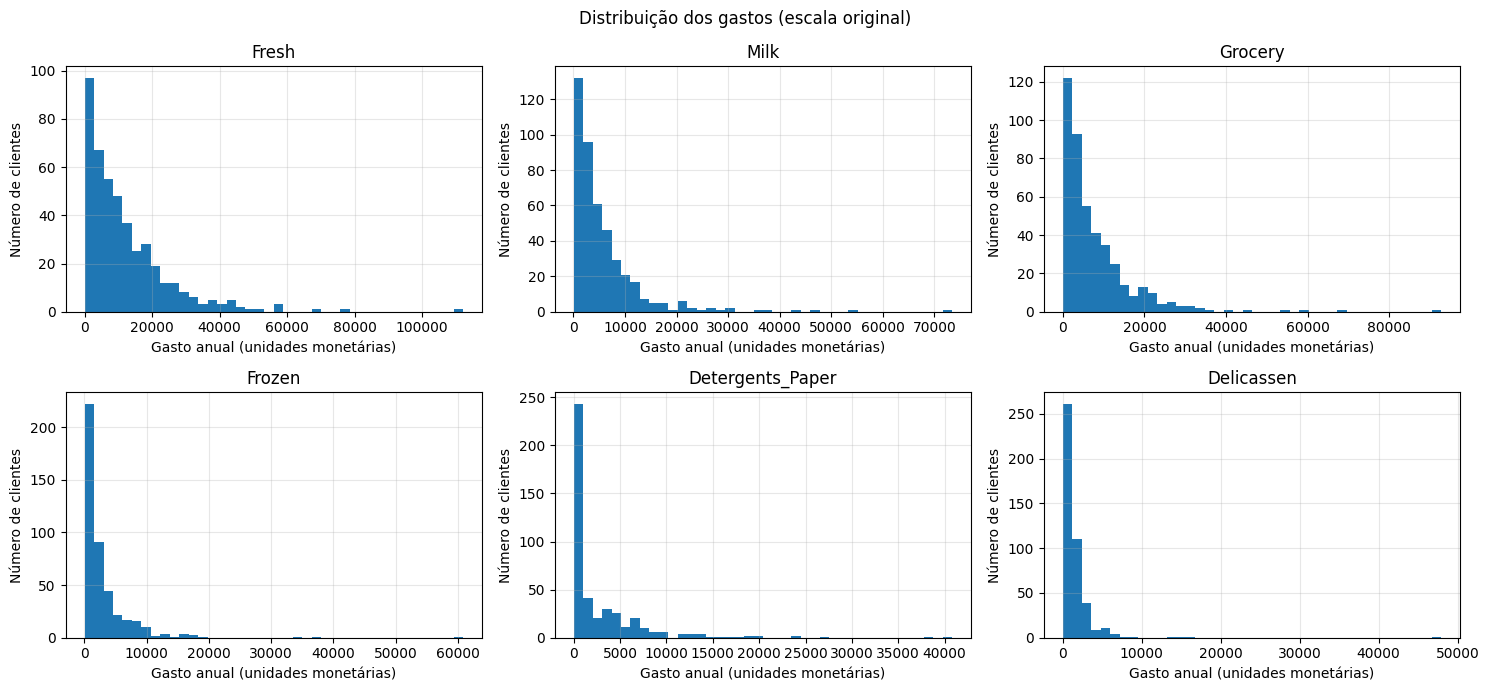

In [5]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axs.ravel(), colunas):
    ax.hist(X[col], bins=40)
    ax.set_title(col)
    ax.set_xlabel("Gasto anual (unidades monetárias)")
    ax.set_ylabel("Número de clientes")
    ax.grid(alpha=0.3)
fig.suptitle("Distribuição dos gastos (escala original)")
fig.tight_layout()
fig.savefig("distribuicoes_originais.png", dpi=300)
plt.show()

Aplicando a transformação logarítmica $x' = \log(1 + x)$ e conferindo o efeito sobre a assimetria e sobre os histogramas:

,assimetria original,assimetria após log1p
Fresh,2.561,-1.575
Milk,4.054,-0.224
Grocery,3.587,-0.675
Frozen,5.908,-0.353
Detergents_Paper,3.632,-0.236
Delicassen,11.152,-1.092


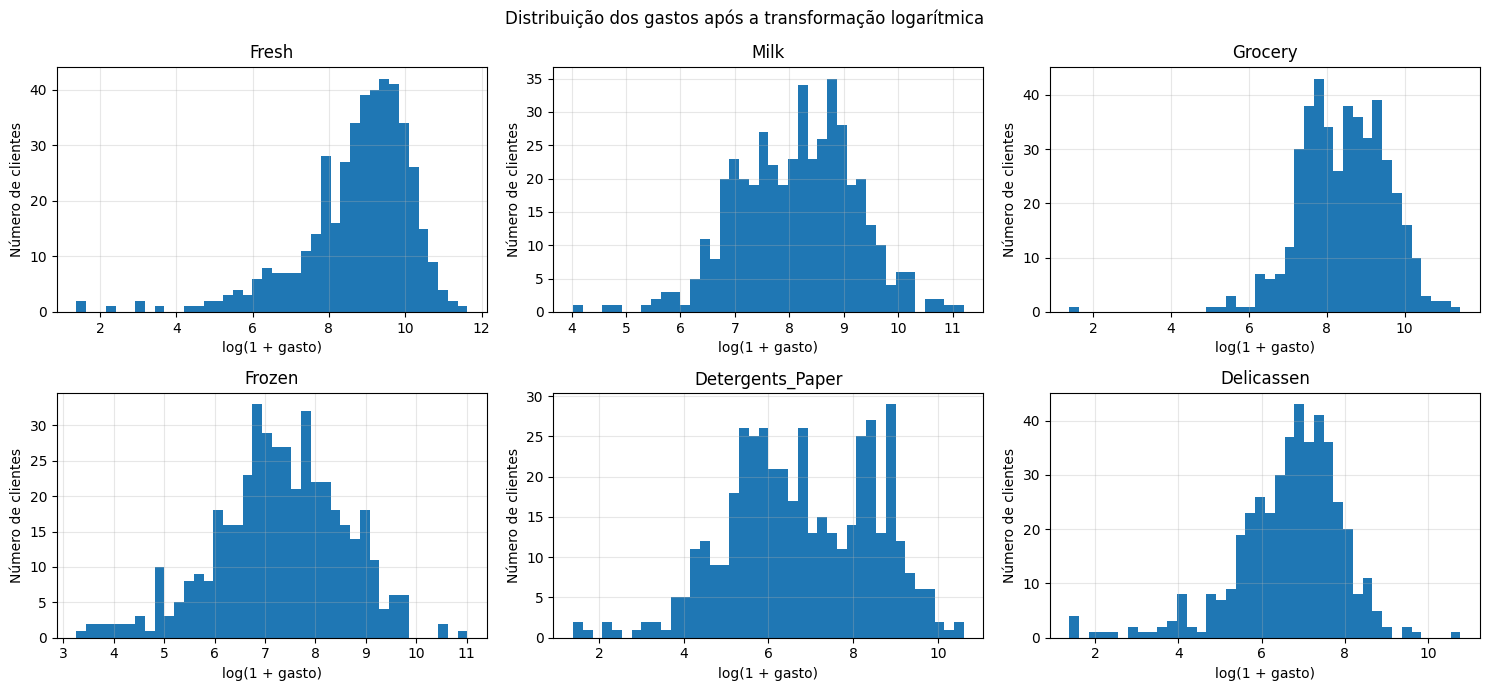

In [6]:
X_log = np.log1p(X)

comparacao = pd.DataFrame({"assimetria original": X.skew(), "assimetria após log1p": X_log.skew()})
display(comparacao.round(3))

fig, axs = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axs.ravel(), colunas):
    ax.hist(X_log[col], bins=40)
    ax.set_title(col)
    ax.set_xlabel("log(1 + gasto)")
    ax.set_ylabel("Número de clientes")
    ax.grid(alpha=0.3)
fig.suptitle("Distribuição dos gastos após a transformação logarítmica")
fig.tight_layout()
fig.savefig("distribuicoes_log.png", dpi=300)
plt.show()

Em seguida, padronizando os atributos por $Z$-score (média 0 e desvio padrão 1), com `StandardScaler`, como no notebook da disciplina. O $k$-means usa a distância euclidiana, então atributos em escalas diferentes dominariam o cálculo das distâncias:

In [7]:
scaler = StandardScaler()
X_pad = scaler.fit_transform(X_log)

print("Média de cada atributo após a padronização:", X_pad.mean(axis=0).round(6))
print("Desvio padrão de cada atributo:            ", X_pad.std(axis=0).round(6))

Média de cada atributo após a padronização: [ 0. -0. -0.  0. -0. -0.]
Desvio padrão de cada atributo:             [1. 1. 1. 1. 1. 1.]


Calculando a matriz de correlação entre as seis categorias, na escala original e após o logaritmo, e destacando o par `Grocery`–`Detergents_Paper`:

Correlação de Pearson (escala original):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Fresh,1.000,0.101,-0.012,0.346,-0.102,0.245
Milk,0.101,1.000,0.728,0.124,0.662,0.406
Grocery,-0.012,0.728,1.000,-0.040,0.925,0.205
Frozen,0.346,0.124,-0.040,1.000,-0.132,0.391
Detergents_Paper,-0.102,0.662,0.925,-0.132,1.000,0.069
Delicassen,0.245,0.406,0.205,0.391,0.069,1.000


Correlação de Pearson (após log1p):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Fresh,1.000,-0.021,-0.133,0.386,-0.159,0.256
Milk,-0.021,1.000,0.761,-0.055,0.679,0.342
Grocery,-0.133,0.761,1.000,-0.165,0.797,0.240
Frozen,0.386,-0.055,-0.165,1.000,-0.213,0.256
Detergents_Paper,-0.159,0.679,0.797,-0.213,1.000,0.168
Delicassen,0.256,0.342,0.240,0.256,0.168,1.000


Grocery x Detergents_Paper (original): 0.925
Grocery x Detergents_Paper (log1p):    0.797


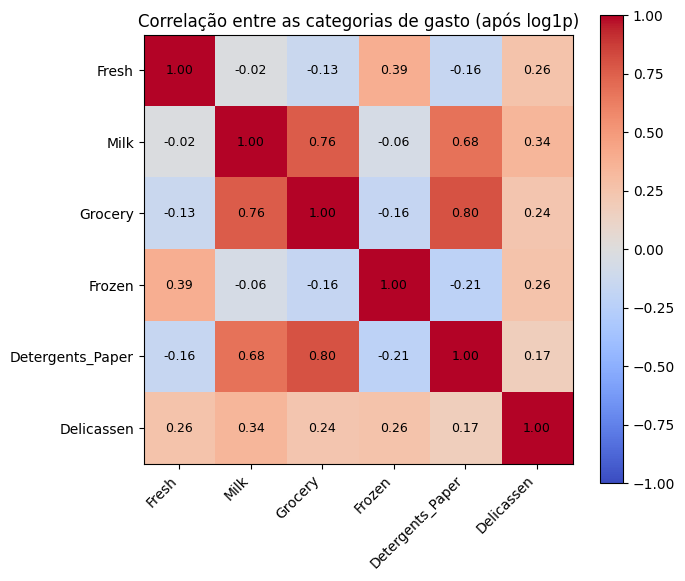

In [8]:
corr_orig = X.corr()
corr_log = X_log.corr()

print("Correlação de Pearson (escala original):")
display(corr_orig.round(3))
print("Correlação de Pearson (após log1p):")
display(corr_log.round(3))

print(f"Grocery x Detergents_Paper (original): {corr_orig.loc['Grocery', 'Detergents_Paper']:.3f}")
print(f"Grocery x Detergents_Paper (log1p):    {corr_log.loc['Grocery', 'Detergents_Paper']:.3f}")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr_log.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(colunas)))
ax.set_xticklabels(colunas, rotation=45, ha="right")
ax.set_yticks(range(len(colunas)))
ax.set_yticklabels(colunas)
for i in range(len(colunas)):
    for j in range(len(colunas)):
        ax.text(j, i, f"{corr_log.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax)
ax.set_title("Correlação entre as categorias de gasto (após log1p)")
fig.tight_layout()
fig.savefig("matriz_correlacao.png", dpi=300)
plt.show()

**Tarefa 2.** Diferentemente dos projetos anteriores, aqui **não se separa um conjunto de teste**. No aprendizado supervisionado, o teste serve para estimar o erro de generalização sobre rótulos conhecidos; no não supervisionado não há rótulo a prever, e o objetivo é descrever a estrutura dos próprios dados. Por isso, a validação de um agrupamento usa critérios internos (como a silhueta) e, quando existe uma referência, externos (como o índice de Rand ajustado), como visto no notebook da disciplina.

**Tarefa 3.** Vamos executar o $k$-means para $K$ de 2 a 10, registrando a inércia (soma dos quadrados intra-cluster) e a silhueta média de cada partição. A coluna "Redução (%)" mede a queda relativa da inércia ao passar de $K-1$ para $K$ (método do cotovelo):

In [9]:
ks = np.arange(2, 11)
inercias, silhuetas = [], []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_pad)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X_pad, km.labels_))

inercias = np.array(inercias)
silhuetas = np.array(silhuetas)

tabela_k = pd.DataFrame({
    "K": ks,
    "Inércia J(K)": inercias.round(1),
    "Redução (%)": np.r_[np.nan, 100 * (inercias[:-1] - inercias[1:]) / inercias[:-1]].round(1),
    "Silhueta média": silhuetas.round(4),
}).set_index("K")
display(tabela_k)

,Inércia J(K),Redução (%),Silhueta média
K,,,
2,1844.1,NaN,0.2903
3,1553.4,15.8,0.2594
4,1386.9,10.7,0.1885
5,1266.1,8.7,0.1916
6,1174.8,7.2,0.2009
7,1086.4,7.5,0.1958
8,1028.5,5.3,0.1852
9,973.1,5.4,0.1965
10,932.0,4.2,0.1905


Plotando a inércia (nas escalas linear e logarítmica, como no notebook da disciplina) e a silhueta média em função de $K$:

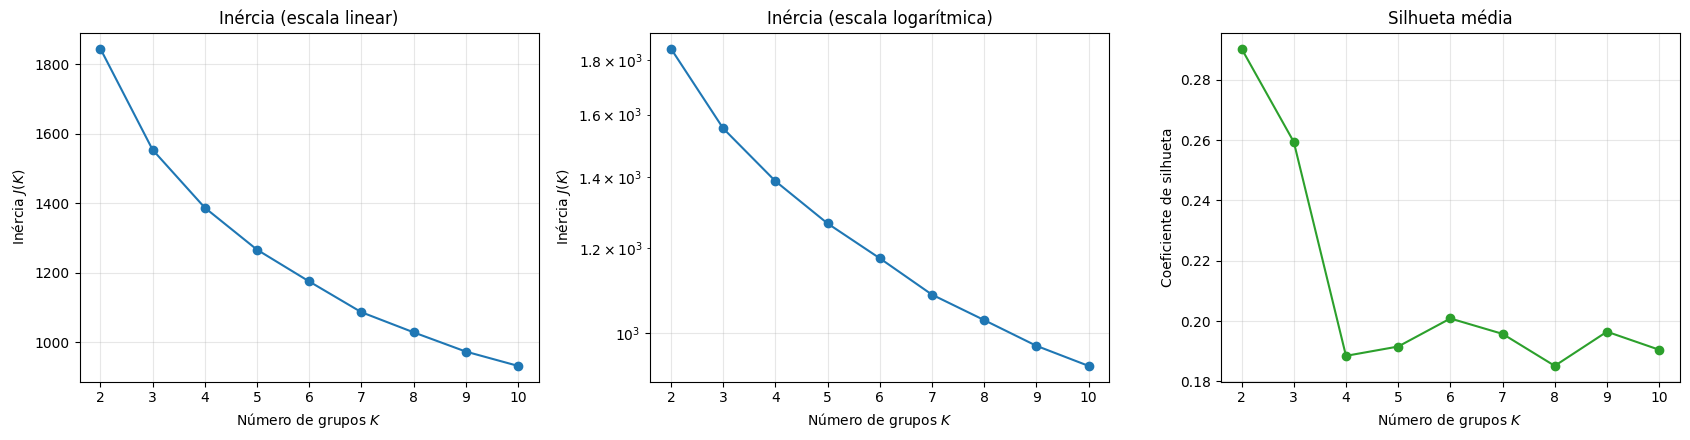

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))

axs[0].plot(ks, inercias, marker="o")
axs[0].set_title("Inércia (escala linear)")
axs[0].set_ylabel("Inércia $J(K)$")

axs[1].plot(ks, inercias, marker="o")
axs[1].set_yscale("log")
axs[1].set_title("Inércia (escala logarítmica)")
axs[1].set_ylabel("Inércia $J(K)$")

axs[2].plot(ks, silhuetas, marker="o", color="tab:green")
axs[2].set_title("Silhueta média")
axs[2].set_ylabel("Coeficiente de silhueta")

for ax in axs:
    ax.set_xlabel("Número de grupos $K$")
    ax.set_xticks(ks)
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("escolha_k.png", dpi=300)
plt.show()

Escolhendo $K$. O código sugere o $K$ de maior silhueta média, mas **a escolha final deve considerar também o cotovelo e a interpretabilidade comercial dos grupos** (um segmento só é útil se a área comercial souber o que fazer com ele). Se, depois de analisar a tabela e os gráficos, a decisão for outro valor, basta alterar `k_escolhido` na célula abaixo e executar as células seguintes:

In [11]:
k_sugerido = int(ks[np.argmax(silhuetas)])
print("K com maior silhueta média:", k_sugerido)

k_escolhido = k_sugerido   # <-- altere aqui se escolher outro K
print("K escolhido:", k_escolhido)

modelo = KMeans(n_clusters=k_escolhido, n_init=10, random_state=42)
rotulos = modelo.fit_predict(X_pad)

print(f"\nInércia: {modelo.inertia_:.4f}")
print(f"Iterações (melhor execução): {modelo.n_iter_}")
print(f"Silhueta média: {silhouette_score(X_pad, rotulos):.4f}")
print("\nClientes por grupo:")
print(pd.Series(rotulos).value_counts().sort_index())

K com maior silhueta média: 2
K escolhido: 2

Inércia: 1844.0641
Iterações (melhor execução): 13
Silhueta média: 0.2903

Clientes por grupo:
0    252
1    188
Name: count, dtype: int64


(Opcional) Caso limite: com $K$ igual ao número de amostras, cada cliente é o próprio centróide e a inércia vale zero. Isso mostra por que a inércia não pode ser usada sozinha para escolher $K$:

In [12]:
km_limite = KMeans(n_clusters=len(X_pad), n_init=1, random_state=0).fit(X_pad)
print(f"Inércia com K = {len(X_pad)} (um centróide por cliente): {km_limite.inertia_:.6f}")

Inércia com K = 440 (um centróide por cliente): 0.000000


**Tarefa 4.** O $k$-means converge para um mínimo local, que depende da inicialização. Vamos executar o algoritmo dez vezes com `init="random"` e `n_init=1`, usando sementes distintas, e registrar a inércia final de cada execução. Depois, repetimos com `init="k-means++"`. Como no notebook da disciplina, contamos também quantas execuções atingem a melhor inércia conhecida (a do modelo com `n_init=10`):

,Inércia (random),Inércia (k-means++)
Semente,,
0,1844.0641,1844.1270
1,1844.0641,1844.0641
2,1844.0641,1844.0641
3,1844.1270,1844.0641
4,1844.0641,1844.1270
5,1844.0641,1844.0641
6,1844.1270,1844.1270
7,1844.1270,1844.1270
8,1844.0641,1844.0641


Melhor inércia conhecida (n_init=10): 1844.0641


,random,k-means++
mínimo,1844.0641,1844.0641
máximo,1844.1270,1844.1270
média,1844.0830,1844.0893
desvio padrão,0.0289,0.0308
amplitude (máx − mín),0.0630,0.0630
execuções que atingiram a melhor inércia,7.0000,6.0000


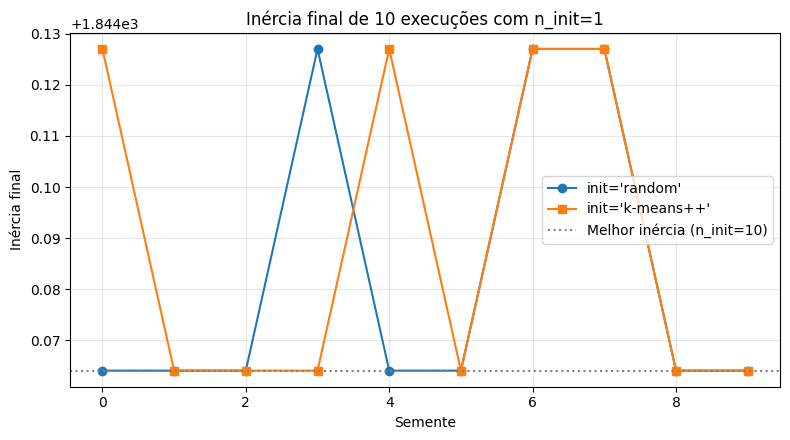

In [13]:
sementes = list(range(10))
J_random = [KMeans(n_clusters=k_escolhido, init="random", n_init=1, random_state=s).fit(X_pad).inertia_
            for s in sementes]
J_pp = [KMeans(n_clusters=k_escolhido, init="k-means++", n_init=1, random_state=s).fit(X_pad).inertia_
        for s in sementes]

tabela_init = pd.DataFrame({"Semente": sementes,
                            "Inércia (random)": J_random,
                            "Inércia (k-means++)": J_pp}).set_index("Semente")
display(tabela_init.round(4))

melhor_J = modelo.inertia_
resumo = pd.DataFrame({
    metodo: {
        "mínimo": np.min(J), "máximo": np.max(J), "média": np.mean(J),
        "desvio padrão": np.std(J), "amplitude (máx − mín)": np.max(J) - np.min(J),
        "execuções que atingiram a melhor inércia": int(np.sum(np.isclose(J, melhor_J, rtol=1e-6))),
    }
    for metodo, J in [("random", J_random), ("k-means++", J_pp)]
})
print(f"Melhor inércia conhecida (n_init=10): {melhor_J:.4f}")
display(resumo.round(4))

plt.figure(figsize=(8, 4.5))
plt.plot(sementes, J_random, marker="o", label="init='random'")
plt.plot(sementes, J_pp, marker="s", label="init='k-means++'")
plt.axhline(melhor_J, color="gray", linestyle=":", label="Melhor inércia (n_init=10)")
plt.xlabel("Semente")
plt.ylabel("Inércia final")
plt.title("Inércia final de 10 execuções com n_init=1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("inicializacao.png", dpi=300)
plt.show()

**Tarefa 5.** Recuperando os centróides e revertendo-os para a escala original de gasto: primeiro desfazemos a padronização (`inverse_transform`) e depois a transformação logarítmica ($\exp(x') - 1$, que em `numpy` é `expm1`):

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Nº de clientes
Grupo 0,8580.6,1753.7,2274.4,2063.8,287.4,649.4,252
Grupo 1,4013.9,8061.6,12051.1,953.5,4035.6,1022.1,188


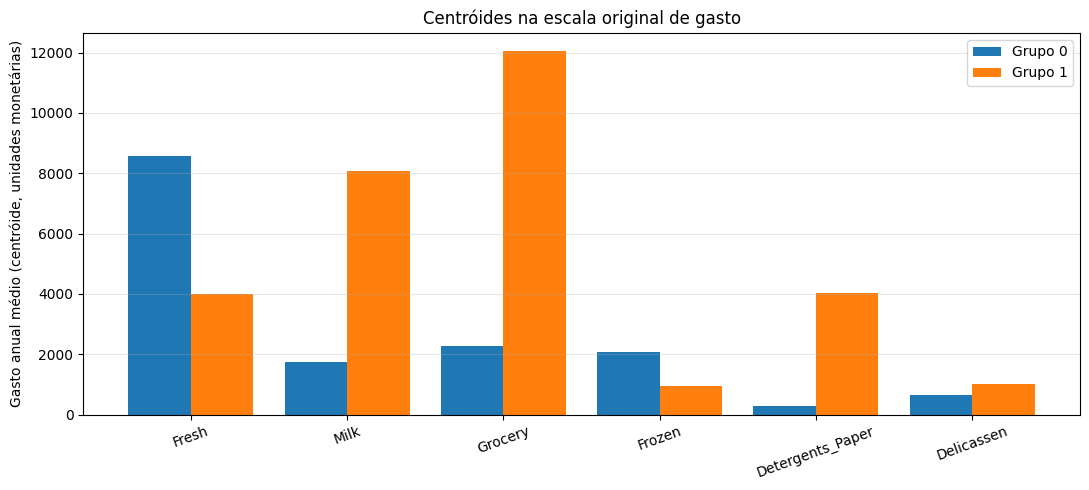

In [14]:
centros_log = scaler.inverse_transform(modelo.cluster_centers_)
centros = np.expm1(centros_log)

tabela_centros = pd.DataFrame(centros, columns=colunas,
                              index=[f"Grupo {g}" for g in range(k_escolhido)])
tabela_centros["Nº de clientes"] = np.bincount(rotulos)
display(tabela_centros.round(1))

fig, ax = plt.subplots(figsize=(11, 5))
largura = 0.8 / k_escolhido
posicoes = np.arange(len(colunas))
for g in range(k_escolhido):
    ax.bar(posicoes + g * largura, centros[g], width=largura, label=f"Grupo {g}")
ax.set_xticks(posicoes + largura * (k_escolhido - 1) / 2)
ax.set_xticklabels(colunas, rotation=20)
ax.set_ylabel("Gasto anual médio (centróide, unidades monetárias)")
ax.set_title("Centróides na escala original de gasto")
ax.legend()
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig("centroides.png", dpi=300)
plt.show()

Validação externa: tabelas de contingência cruzando o grupo de cada cliente com `Channel` e com `Region`, e o índice de Rand ajustado (ARI) entre a partição obtida e as variáveis `Channel` e `Region`. O ARI vale 1 para partições idênticas e fica próximo de 0 para partições aleatórias:

In [15]:
grupo = pd.Series(rotulos, name="Grupo")
canal_nome = canal.map({1: "Horeca", 2: "Retail"}).rename("Canal").reset_index(drop=True)
regiao_nome = regiao.map({1: "Lisboa", 2: "Porto", 3: "Outras"}).rename("Região").reset_index(drop=True)

cont_canal = pd.crosstab(grupo, canal_nome)
cont_regiao = pd.crosstab(grupo, regiao_nome)

print("Grupo x Canal (contagens):")
display(cont_canal)
print("Grupo x Canal (% de cada grupo):")
display((pd.crosstab(grupo, canal_nome, normalize="index") * 100).round(1))

print("Grupo x Região (contagens):")
display(cont_regiao)
print("Grupo x Região (% de cada grupo):")
display((pd.crosstab(grupo, regiao_nome, normalize="index") * 100).round(1))

print(f"ARI (grupos x Channel): {adjusted_rand_score(canal, rotulos):.4f}")
print(f"ARI (grupos x Region):  {adjusted_rand_score(regiao, rotulos):.4f}")

Grupo x Canal (contagens):


Canal,Horeca,Retail
Grupo,,
0,244,8
1,54,134


Grupo x Canal (% de cada grupo):


Canal,Horeca,Retail
Grupo,,
0,96.8,3.2
1,28.7,71.3


Grupo x Região (contagens):


Região,Lisboa,Outras,Porto
Grupo,,,
0,48,176,28
1,29,140,19


Grupo x Região (% de cada grupo):


Região,Lisboa,Outras,Porto
Grupo,,,
0,19.0,69.8,11.1
1,15.4,74.5,10.1


ARI (grupos x Channel): 0.5135
ARI (grupos x Region):  -0.0077


Para responder qual conjunto de categorias de produto mais separa Horeca de Retail, comparamos o gasto médio padronizado de cada canal em cada categoria (a maior diferença indica a categoria que mais os separa):

In [16]:
medias_canal = pd.DataFrame(X_pad, columns=colunas).groupby(canal_nome.values).mean()
display(medias_canal.round(3))

diferenca = (medias_canal.loc["Retail"] - medias_canal.loc["Horeca"]).sort_values(key=abs, ascending=False)
print("Diferença (Retail − Horeca) no gasto médio padronizado, da maior para a menor em módulo:")
print(diferenca.round(3))

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Horeca,0.117,-0.398,-0.458,0.169,-0.502,-0.091
Retail,-0.246,0.836,0.960,-0.355,1.053,0.190


Diferença (Retail − Horeca) no gasto médio padronizado, da maior para a menor em módulo:
Detergents_Paper    1.555
Grocery             1.418
Milk                1.235
Frozen             -0.524
Fresh              -0.363
Delicassen          0.281
dtype: float64


Por fim, projetando os dados em duas dimensões por PCA e colorindo os pontos pelo agrupamento (à esquerda) e, para comparação, pelo canal de venda (à direita). Os centróides também são projetados:

Variância explicada por componente: [0.4408 0.2719]
Variância explicada acumulada (2D): 71.27%


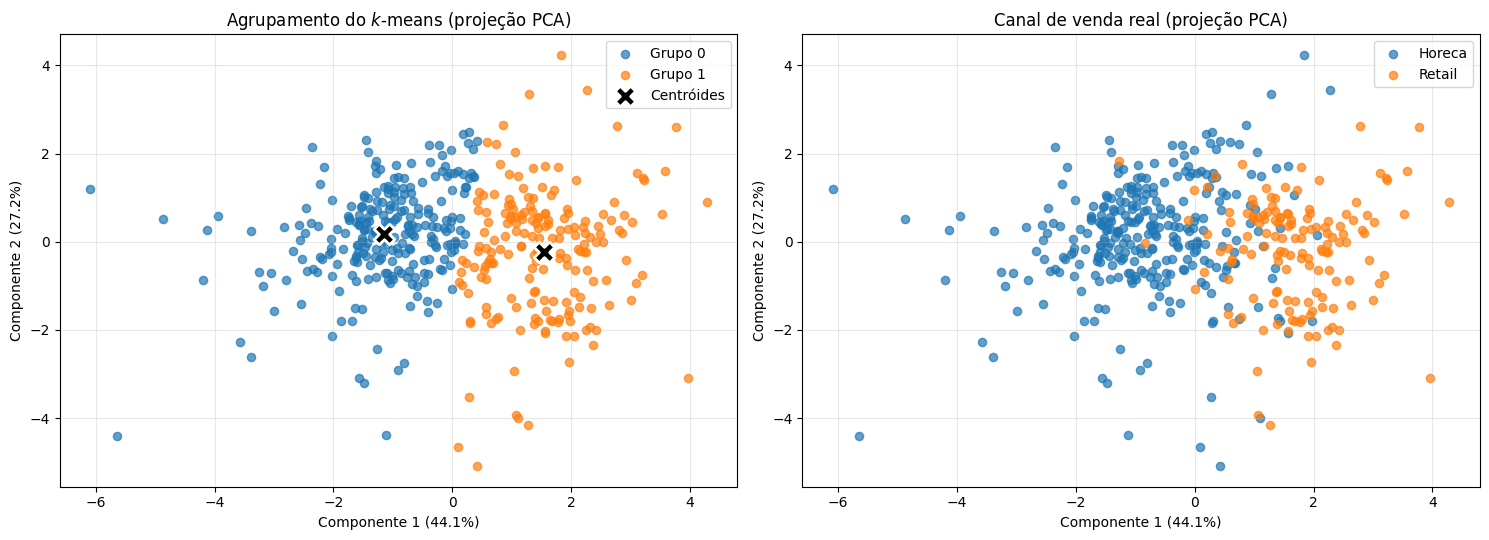

In [17]:
pca = PCA(n_components=2)
Z = pca.fit_transform(X_pad)
Zc = pca.transform(modelo.cluster_centers_)

print("Variância explicada por componente:", pca.explained_variance_ratio_.round(4))
print(f"Variância explicada acumulada (2D): {pca.explained_variance_ratio_.sum():.2%}")

fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))

for g in range(k_escolhido):
    mask = rotulos == g
    axs[0].scatter(Z[mask, 0], Z[mask, 1], s=35, alpha=0.7, label=f"Grupo {g}")
axs[0].scatter(Zc[:, 0], Zc[:, 1], marker="X", s=220, c="black", edgecolors="white",
               linewidths=2, label="Centróides", zorder=5)
axs[0].set_title("Agrupamento do $k$-means (projeção PCA)")

for nome in ["Horeca", "Retail"]:
    mask = (canal_nome == nome).values
    axs[1].scatter(Z[mask, 0], Z[mask, 1], s=35, alpha=0.7, label=nome)
axs[1].set_title("Canal de venda real (projeção PCA)")

for ax in axs:
    ax.set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.1%})")
    ax.set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]:.1%})")
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("pca_grupos.png", dpi=300)
plt.show()

Baixando as figuras para usar no relatório (o armazenamento do Colab é temporário):

In [18]:
from google.colab import files
for arq in ["distribuicoes_originais.png", "distribuicoes_log.png", "matriz_correlacao.png",
            "escolha_k.png", "inicializacao.png", "centroides.png", "pca_grupos.png"]:
    files.download(arq)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>